In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor,
                              StackingRegressor)
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print('Библиотеки scikit-learn подключены')

Библиотеки scikit-learn подключены


In [2]:
# Исходные данные UCI Student Performance (математика)
# Перед запуском скачайте student-mat.csv и положите рядом с Notebook.
from pathlib import Path
DATA_FILE = Path('student-mat.csv')
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        'Файл student-mat.csv не найден. Скачайте архив Student Performance '
        'с сайта UCI, извлеките student-mat.csv и поместите его в рабочую папку.'
    )
df = pd.read_csv(DATA_FILE, sep=';')
print('Размер данных:', df.shape)
print('Пропусков:', int(df.isna().sum().sum()))
print('Оценка G3: минимум =', df['G3'].min(), ', максимум =', df['G3'].max())
print(df[['studytime','absences','G1','G2','G3']].head().to_string(index=False))

Размер данных: (395, 33)
Пропусков: 0
Оценка G3: минимум = 0 , максимум = 20
 studytime  absences  G1  G2  G3
         2         6   5   6   6
         2         4   5   5   6
         2        10   7   8  10
         3         2  15  14  15
         2         4   6  10  10


In [3]:
X = df.drop(columns='G3')
y = df['G3'].astype(float)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=16)
print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

Обучающая выборка: (316, 32)
Тестовая выборка: (79, 32)


In [4]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False))]), cat_cols),
], sparse_threshold=0)
print('Числовых признаков:',len(num_cols))
print('Категориальных признаков:',len(cat_cols))

Числовых признаков: 15
Категориальных признаков: 17


In [5]:
results = []
models = {}
def evaluate(name, regressor):
    model = Pipeline([('preprocess', preprocess),('model',regressor)])
    model.fit(X_train,y_train)
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test,pred)
    rmse = np.sqrt(mean_squared_error(y_test,pred))
    r2 = r2_score(y_test,pred)
    results.append({'Модель':name,'MAE':mae,'RMSE':rmse,'R²':r2})
    models[name]=model
    print(f'{name}: MAE={mae:.4f}; RMSE={rmse:.4f}; R²={r2:.4f}')
    return pred

In [6]:
bag_pred = evaluate('Бэггинг', BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=5,random_state=16),
    n_estimators=100,random_state=16,n_jobs=-1))

Бэггинг: MAE=1.2264; RMSE=1.9279; R²=0.8471


In [7]:
forest_pred = evaluate('Случайный лес', RandomForestRegressor(
    n_estimators=150,max_depth=7,min_samples_leaf=2,
    random_state=16,n_jobs=-1))

Случайный лес: MAE=1.2238; RMSE=1.9809; R²=0.8386


In [8]:
ada_pred = evaluate('AdaBoost', AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3,random_state=16),
    n_estimators=100,learning_rate=0.05,random_state=16))

AdaBoost: MAE=1.3447; RMSE=1.9692; R²=0.8405


In [9]:
gb_pred = evaluate('Градиентный бустинг', GradientBoostingRegressor(
    n_estimators=150,learning_rate=0.05,max_depth=3,
    random_state=16))

Градиентный бустинг: MAE=1.2384; RMSE=1.9658; R²=0.8411


             Модель    MAE   RMSE     R²
      Случайный лес 1.2238 1.9809 0.8386
            Бэггинг 1.2264 1.9279 0.8471
Градиентный бустинг 1.2384 1.9658 0.8411
           AdaBoost 1.3447 1.9692 0.8405


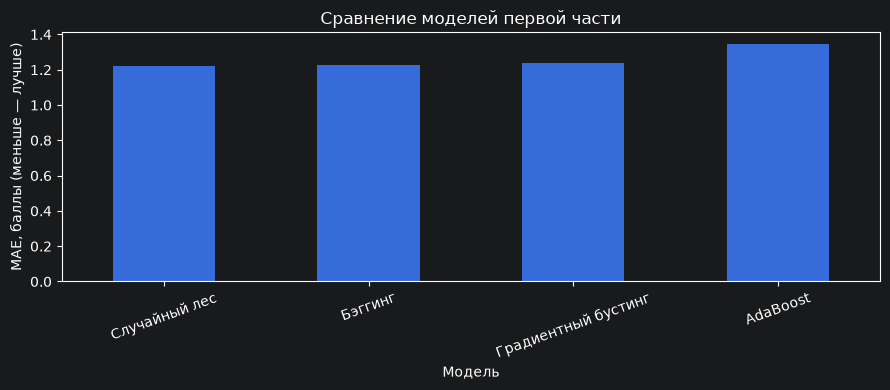

In [10]:
summary = pd.DataFrame(results).sort_values('MAE')
print(summary.to_string(index=False, formatters={
    'MAE':'{:.4f}'.format, 'RMSE':'{:.4f}'.format, 'R²':'{:.4f}'.format
}))
ax = summary.plot.bar(x='Модель', y='MAE', legend=False,
                      figsize=(9, 4), rot=20)
ax.set_ylabel('MAE, баллы (меньше — лучше)')
ax.set_title('Сравнение моделей первой части')
plt.tight_layout()
plt.show()

In [11]:
comparison = pd.DataFrame({
    'Номер ученика': X_test.index + 1,
    'Реальная G3': y_test.to_numpy(),
    'Бэггинг': bag_pred,
    'Случайный лес': forest_pred,
    'AdaBoost': ada_pred,
    'Градиентный бустинг': gb_pred
})
print(comparison.head(10).round(2).to_string(index=False))

 Номер ученика  Реальная G3  Бэггинг  Случайный лес  AdaBoost  Градиентный бустинг
           305         13.0    14.10          14.15     14.55                14.50
           332         14.0    14.32          14.34     14.55                14.07
           217          4.0     6.25           6.13      6.47                 6.03
            31         12.0    10.51          10.51     11.29                11.44
           191         13.0    11.71          11.75     11.73                11.81
           201         16.0    16.12          16.21     15.59                16.08
           321         13.0    13.15          13.28     13.10                13.00
           158         10.0     8.52           8.53      8.87                 8.91
           175          9.0    10.68          10.77     11.29                10.87
           334          0.0     2.92           2.36      3.36                 3.05
